# 01 · Predicción de precio (CABA, departamentos en venta, USD)

Modelo A del proyecto. El pipeline completo vive en `ml/precio.py` (lo usa también la sección **Modelos** de la interfaz), así que lo que se ve acá es exactamente lo que entrena la app. Documentación: `docs/modelo_precio.md`.

1. **Datos**: `data/listings.jsonl` (última versión de cada aviso), filtro CABA.
2. **Limpieza**: reglas de consistencia, pozo/emprendimientos fuera, casi-duplicados fuera (filas en cada paso).
3. **Separación**: test fijo del 20 % **agrupado** por unidad física: la misma propiedad nunca está en train y en test.
4. **Recorte de USD/m²** (percentiles 1–99) calculado **sólo con train**, también dentro de cada fold.
5. **CV de 5 folds agrupados** en train: baselines, Ridge y grilla de LightGBM con early stopping.
6. **Evaluación única** en test, calibración del intervalo de 80 % y análisis de errores.

Kernel: el Python de `ml/.venv` (ver README, sección *Modelos*).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'ml'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import zpml, precio
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

P = dict(operacion='venta', currency='USD', tipo='departamento', split='agrupado', test_size=0.2, seed=42,
         variante='v4_todo_sin_iso', hiperparametros='optuna',  # iteración 4: parámetros de ml/optuna_precio.py (CV agrupado en train)
         cv_folds=5, tune=True, trim_pct=1.0, excluir_pozo=True)

## 1. Datos

In [2]:
df = zpml.load()          # sólo CABA, una fila por id
print(f'{len(df):,} avisos de CABA · scrape del {df.scraped_at.min()[:10]} al {df.scraped_at.max()[:10]}')
df['operacion'].value_counts()

105,413 avisos de CABA · scrape del 2026-10-15 al 2026-10-16


operacion
venta                83496
alquiler             19061
alquiler-temporal     2856
Name: count, dtype: int64

## 2. Limpieza

Reglas (constantes en `ml/precio.py`):

- superficie 18–1000 m², cubierta ≤ total; ambientes 1–10, dormitorios ≤ ambientes, baños 1–6, ≥ 9 m² por ambiente;
- precio USD 20.000–15.000.000 y USD/m² 500–15.000 (descarta pesos cargados como dólares y precios parciales);
- avisos de **pozo / en construcción / preventa / anticipo** (su precio suele ser parcial);
- expensas fuera de 200–30.000 ARS/m² y cocheras > 6 pasan a **faltante** (no se descarta el aviso);
- **casi-duplicados**: misma huella *barrio + m² + ambientes + dormitorios + baños + precio redondeado a ~2 %* (queda el más reciente).

Estas reglas son fijas (no se ajustan con los datos), así que aplicarlas antes de separar no filtra información del test.

In [3]:
d, pasos = precio.limpiar(df, P['operacion'], P['currency'], P['tipo'])
pd.DataFrame(pasos)

,paso,filas,quitadas
0,Avisos de CABA (última versión de cada id),105413,0
1,Operación = venta,83496,21917
2,Tipo = departamento,54704,28792
3,Moneda = USD,54607,97
4,Con precio y superficie,54220,387
5,Superficie entre 18 y 1000 m² y cubierta ≤ total,54097,123
6,"Ambientes 1–10, dormitorios ≤ ambientes, baños...",53979,118
7,"Precio USD 20,000–15,000,000 y USD/m² 500–15,000",53889,90
8,Sin pozo / en construcción / emprendimiento (p...,47882,6007
9,Sin duplicados (misma huella Y misma calle/alt...,45629,2253


pozo detectados (antes de excluir): 5564


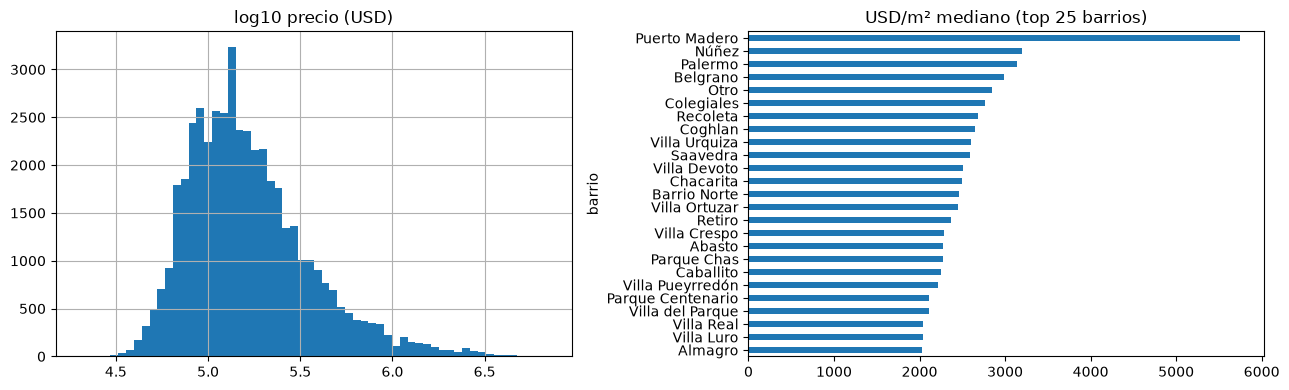

In [4]:
print('pozo detectados (antes de excluir):', precio.limpiar(df, excluir_pozo=False)[0]['pozo'].sum())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
np.log10(d['price_x']).hist(bins=60, ax=ax[0]); ax[0].set_title('log10 precio (USD)')
d.groupby('barrio')['ppm2'].median().sort_values().tail(25).plot.barh(ax=ax[1], title='USD/m² mediano (top 25 barrios)')
plt.tight_layout()

## 3. Variables

Estructurales del aviso (superficie, ambientes, dormitorios, baños, cocheras, expensas y derivadas), barrio, y cuatro atributos que se buscan en título/descripción/etiquetas **después de borrar los montos** (a estrenar, balcón/terraza, amenities, apto crédito). El formulario de predicción pide esos cuatro como casillas.

Quedaron **afuera**: días publicado, destacado/super destacado, cantidad de fotos y tipo de publicación: describen el aviso, no la propiedad, y la predicción no los puede conocer.

In [5]:
X, nums, cats = zpml.build_features(d.reset_index(drop=True))
print('numéricas:', nums); print('categóricas:', cats)
X.isna().mean().sort_values(ascending=False).head(10).rename('faltantes')

numéricas: ['superficie_total', 'ambientes', 'dormitorios', 'banos', 'cocheras', 'expensas', 'superficie', 'log_superficie', 'expensas_m2', 'm2_por_ambiente', 'kw_a_estrenar', 'kw_balcon_terraza', 'kw_amenities', 'kw_apto_credito']
categóricas: ['barrio', 'tipo_prop']


cocheras           0.76
expensas           0.29
expensas_m2        0.29
dormitorios        0.17
banos              0.02
ambientes          0.01
m2_por_ambiente    0.01
superficie_total   0.00
log_superficie     0.00
superficie         0.00
Name: faltantes, dtype: float64

## 4–6. Separación, CV y evaluación
`precio.entrenar` hace todo el pipeline (≈ 2–3 min).

In [6]:
r = precio.entrenar(df, P)
print(f"train {len(r['tr']):,} · test {len(r['te']):,} · grupos en ambos lados: {r['grupos_compartidos']}")
pd.DataFrame(r['pasos'][-1:])

train 35,602 · test 9,300 · grupos en ambos lados: 0


,paso,filas,quitadas
0,Train: recorte de USD/m² percentiles 1–99 (cal...,35602,727


### Validación cruzada (5 folds agrupados sobre train, media ± desvío)

In [7]:
cvt = pd.DataFrame({k: {m: f"{v[m+'_media']:.2f} ± {v[m+'_std']:.2f}" for m in ['MAPE_mediana_%', 'dentro_10%_%', 'R2_log']} | {'MAE': f"{v['MAE_media']:,.0f} ± {v['MAE_std']:,.0f}"} for k, v in r['cv'].items()}).T
cvt

,MAPE_mediana_%,dentro_10%_%,R2_log,MAE
Mediana global,45.42 ± 1.16,11.58 ± 0.28,-0.03 ± 0.02,"143,882 ± 4,919"
Mediana USD/m² del barrio × m²,18.65 ± 0.36,28.30 ± 0.70,0.84 ± 0.00,"69,289 ± 2,207"
Ridge,14.31 ± 0.11,36.58 ± 0.30,0.89 ± 0.00,"56,448 ± 1,417"
LightGBM,10.06 ± 0.30,49.85 ± 1.04,0.94 ± 0.00,"39,603 ± 1,794"
LightGBM v1 (referencia),13.19 ± 0.14,39.51 ± 0.57,0.91 ± 0.00,"50,574 ± 2,085"
LightGBM sin dirección (respaldo),11.08 ± 0.28,46.00 ± 0.77,0.93 ± 0.00,"43,471 ± 1,850"


In [8]:
print('Ridge alpha elegido:', r['ridge_alpha']); print('LightGBM elegido:', r['params_lgb'])
r['tuning'][['num_leaves', 'min_child_samples', 'reg_lambda', 'n_arboles', 'MAPE_mediana_%_media', 'MAPE_mediana_%_std']].sort_values('MAPE_mediana_%_media')

Ridge alpha elegido: 3.0
LightGBM elegido: {'num_leaves': 232, 'min_child_samples': 23, 'learning_rate': 0.020210354655229124, 'reg_lambda': 6.612511707027299, 'n_estimators': {'todo': 3018}}


,num_leaves,min_child_samples,reg_lambda,n_arboles,MAPE_mediana_%_media,MAPE_mediana_%_std
0,232,23,6.61,{'todo': 3018},10.06,0.30


### Test (evaluación única con los hiperparámetros elegidos por CV)

In [9]:
pd.DataFrame(r['test']).T

,MAE,MAPE_mediana_%,dentro_10%_%,R2_log,R2
Mediana global,"148,643.68",47.50,10.63,-0.02,-0.08
Mediana USD/m² del barrio × m²,"69,358.76",18.51,28.86,0.85,0.67
Ridge,"57,595.50",14.39,36.83,0.90,0.75
LightGBM v1 (referencia),"50,508.24",13.33,39.12,0.92,0.80
LightGBM,"38,849.89",9.90,50.40,0.95,0.85
LightGBM sin dirección (respaldo),"42,937.45",10.93,46.61,0.94,0.84


### Comparación con el protocolo anterior
Mismo modelo, pero **sin quitar casi-duplicados y con split aleatorio** (cómo se medía el 12,1 % original). La diferencia es el optimismo que daba tener la misma propiedad en train y en test.

In [10]:
comp = precio.comparar_aleatorio(df, P, r['params_lgb'], r['variante'])
print(f"test con otro aviso del mismo grupo en train: {comp['test_con_gemelo_en_train_%']:.1f} %")
pd.DataFrame({'protocolo anterior (aleatorio, con duplicados)': comp['metricas'], 'nuevo (agrupado, sin duplicados)': r['test']['LightGBM']}).T

test con otro aviso del mismo grupo en train: 72.8 %


,MAE,MAPE_mediana_%,dentro_10%_%,R2_log,R2
"protocolo anterior (aleatorio, con duplicados)","36,028.78",9.19,53.32,0.95,0.87
"nuevo (agrupado, sin duplicados)","38,849.89",9.90,50.40,0.95,0.85


### Calibración del intervalo
Los cuantiles 10/90 y 25/75 salen de los residuos **fuera de fold** del CV (train); acá se mide qué porcentaje del test cae adentro.

In [11]:
print('cuantiles (log):', {k: round(v, 3) for k, v in r['resid_log_quantiles'].items()})
print('cobertura en test:', {k: f'{v:.1f} %' for k, v in r['cobertura'].items()})

cuantiles (log): {'q10': -0.208, 'q25': -0.103, 'q50': -0.003, 'q75': 0.097, 'q90': 0.206}
cobertura en test: {'80%': '80.7 %', '50%': '50.3 %'}


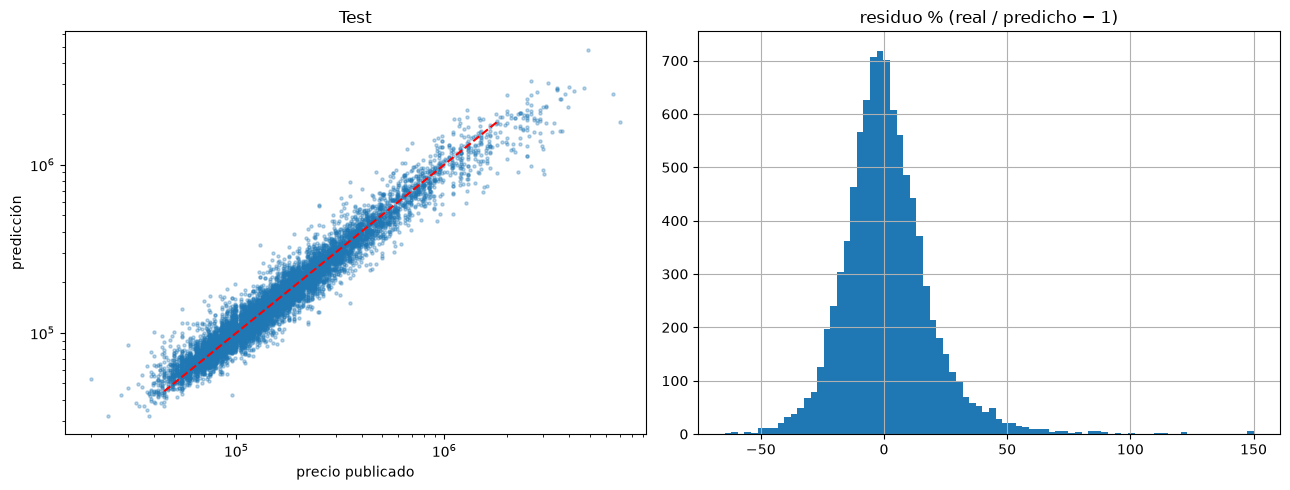

In [12]:
out = r['pred_test']
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(out['price_x'], out['pred'], s=5, alpha=.3); lim = np.percentile(out['price_x'], [1, 99]); ax[0].plot(lim, lim, 'r--')
ax[0].set_xscale('log'); ax[0].set_yscale('log'); ax[0].set_xlabel('precio publicado'); ax[0].set_ylabel('predicción'); ax[0].set_title('Test')
out['residuo_%'].clip(-80, 150).hist(bins=80, ax=ax[1]); ax[1].set_title('residuo % (real / predicho − 1)')
plt.tight_layout()

## 7. Análisis de errores (test)
Sesgo positivo = el mercado publica más caro de lo que predice el modelo.

In [13]:
errs = precio.analisis_errores(out)
errs['superficie_m2']

,n,MAPE_mediana_%,dentro_10%_%,sesgo_mediano_%
sup,,,,
<35,"1,303.00",9.10,54.26,-0.34
35–50,"2,218.00",9.15,53.83,0.03
50–70,"1,886.00",9.74,51.17,-0.27
70–100,"1,725.00",9.68,51.36,-0.26
100–150,"1,177.00",10.34,48.51,-0.93
150+,991.00,13.86,36.73,0.50


In [14]:
errs['precio_usd']

,n,MAPE_mediana_%,dentro_10%_%,sesgo_mediano_%
price_x,,,,
<80k,"1,705.00",10.36,48.15,-6.25
80–120k,"2,052.00",9.45,52.68,-1.09
120–180k,"1,989.00",9.14,53.59,1.05
180–300k,"1,835.00",9.58,51.93,1.83
300–600k,"1,102.00",10.56,47.73,3.07
600k+,617.00,13.78,38.90,8.41


In [15]:
errs['barrio']   # barrios con ≥ 30 avisos en test, de menor a mayor error

,n,MAPE_mediana_%,dentro_10%_%,sesgo_mediano_%
barrio,,,,
Villa Santa Rita,70.00,5.01,74.29,0.24
Chacarita,49.00,7.00,61.22,0.71
Villa Urquiza,293.00,7.10,61.43,-0.38
Saavedra,115.00,7.37,59.13,1.19
Colegiales,149.00,8.11,60.40,0.91
Coghlan,72.00,8.45,56.94,0.20
Villa Devoto,197.00,8.46,58.38,-0.74
Villa Ortuzar,54.00,8.51,57.41,0.97
Villa Crespo,241.00,8.67,57.68,-1.05


## 8. Explicación (importancia y SHAP)

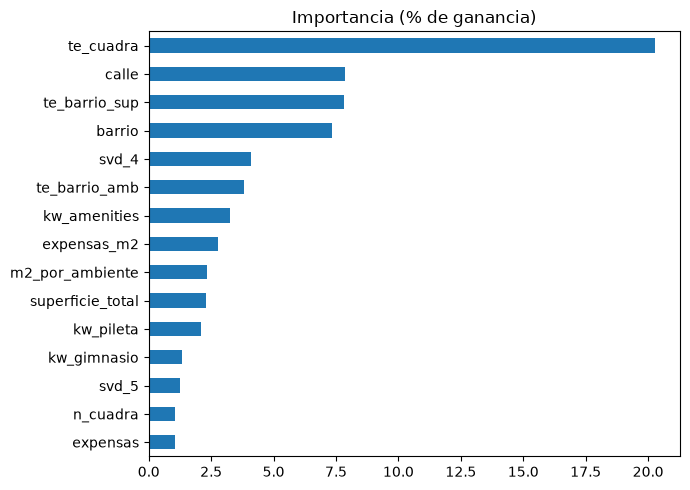

In [16]:
g = r['gbm']
imp = pd.Series(g.booster_.feature_importance('gain'), index=g.feature_name_).sort_values()
(imp / imp.sum() * 100).tail(15).plot.barh(figsize=(7, 5), title='Importancia (% de ganancia)'); plt.tight_layout()

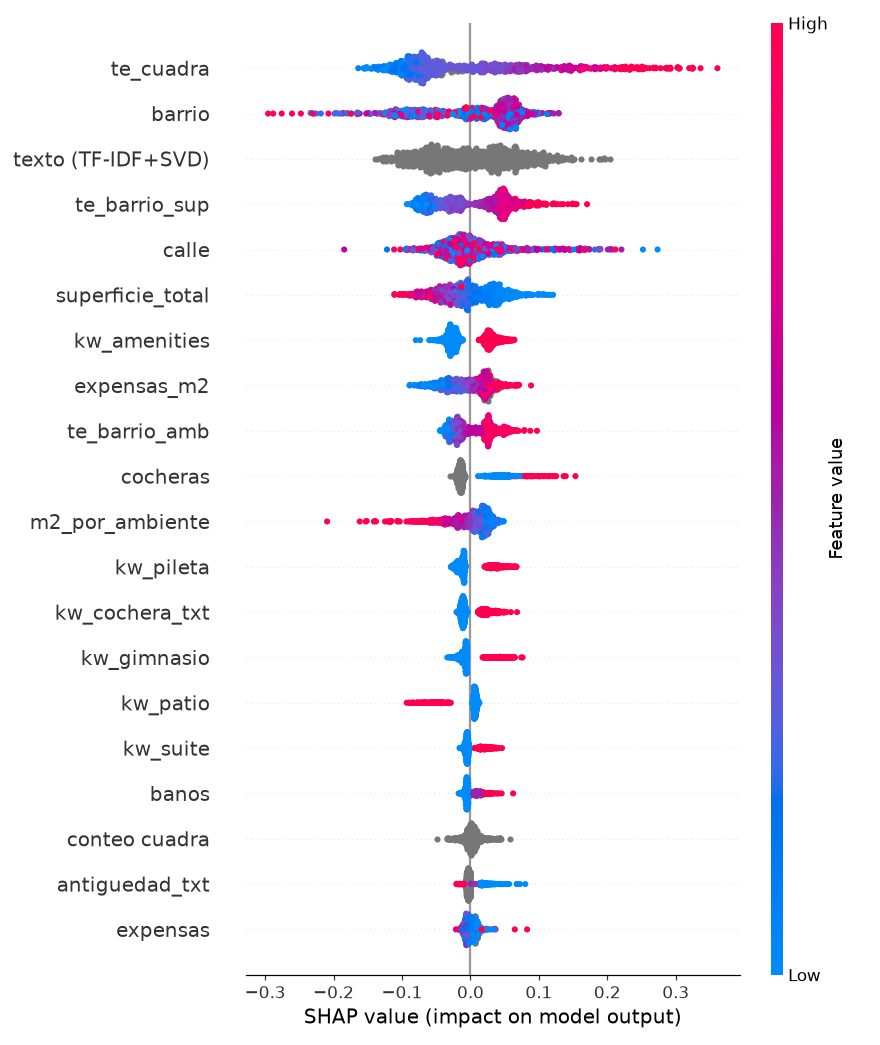

,grupo,shap_abs_medio
0,te_cuadra,0.086396
1,barrio,0.059046
2,texto (TF-IDF+SVD),0.055475
3,te_barrio_sup,0.048821
4,calle,0.034582
5,superficie_total,0.033107
6,kw_amenities,0.029420
7,expensas_m2,0.025630
8,te_barrio_amb,0.025186
9,cocheras,0.024353


In [17]:
# SHAP agrupado (iteraci?n 4): lo calcula ml/run.py sobre la matriz interna del modelo y suma las 30
# componentes de texto en un solo grupo. Se muestra el gr?fico de la corrida final.
from IPython.display import Image, display
RUN_FINAL = ROOT / 'data' / 'ml' / 'runs' / '20261016-193214-price'
display(Image(filename=str(RUN_FINAL / 'shap_summary.png')))
pd.read_csv(RUN_FINAL / 'shap_agrupado.csv').head(12)

## 9. Conclusiones

Ver `docs/modelo_precio.md`: métricas finales, limitaciones (precios publicados, no de cierre; fecha del scrape; dólar MEP) y cómo reproducir.